# Lesson 8 | Deep Learning

# 8.2 Tensorflow and Keras

*   Installing TensorFlow
*   Loading images

In [5]:
!uv add tensorflow

Resolved 146 packages in 20ms
Checked 77 packages in 25ms


If you don't have a GPU on your computer, this is all you need. With a
GPU the setup is a bit more involved. I'm not an expert in that - I
usually prefer cloud solutions where everything is already configured,
so I can just create a notebook and start training. Later in this
module I use Amazon SageMaker notebooks that already have TensorFlow
installed. In this video I still use my laptop - you can see it's
localhost.

## Importing the libraries

Once installed, we import TensorFlow and Keras:

In [6]:
import tensorflow as tf
from tensorflow import keras

In [11]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Loading an image

Now let's load one of the images from the clothing dataset. There is a
special function in Keras for that - `load_img`:

In [7]:
from keras.preprocessing.image import load_img

If you find older tutorials online, you may see the import written as
`from tensorflow.keras.preprocessing.image import load_img`, with
`tensorflow` behind. That was valid when Keras was a separate
library. You can take such code, add `tensorflow` behind, and it
should work without changes.


Let's load a t-shirt from the train folder. We build the path with an
f-string and pass it to `load_img`:

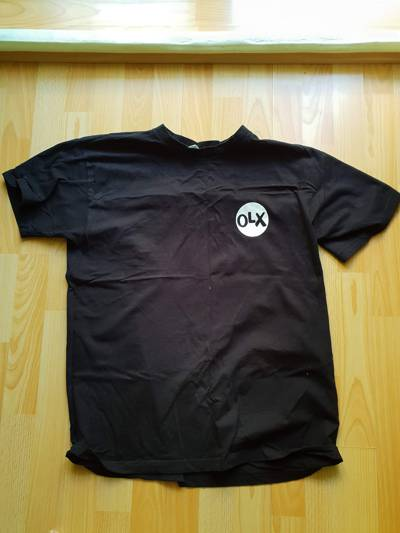

In [8]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

This is actually a Machine Learning Zoomcamp t-shirt - I think I even
recorded a couple of videos wearing it.

## Resizing with target_size

A neural network expects an image of a certain size. Common sizes are
299x299, 224x224, or smaller ones like 150x150:

<p align="center">
  <img src="./images/02-tensorflow-keras-05-image-sizes.svg" alt="Common input sizes for neural networks: 299x299 and 224x224" width="640">
</p>

If we have an image of a different size, we need to resize it to one
of these formats. We do that with the `target_size` parameter:


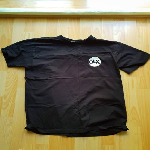

In [9]:
img = load_img(fullname, target_size=(150, 150))
img

In [10]:
print(img)

<PIL.Image.Image image mode=RGB size=150x150 at 0x10B8DFA10>


The library behind this is PIL - the Python Imaging Library. It's what
many libraries use for processing images, and `load_img` returns a PIL
image.

## How images are represented

Internally, an image is just an array with three channels: red, green
and blue. Each channel is an array, and each cell of that array is a
number between 0 and 255 - that's one byte:

<p align="center">
  <img src="./images/02-tensorflow-keras-07-rgb-channels.svg" alt="An image as three channels; the green channel is a grid of numbers from 0 to 255" width="640">
</p>

Each pixel combines three values: one from the red channel, one from
the green channel and one from the blue channel. Our t-shirt is almost
black, so for a pixel on the shirt all three values are probably
almost zero.

## From image to NumPy array

We can turn a PIL image into a NumPy array by simply wrapping it in
`np.array`:

In [ ]:
x = np.array(img) # many columns and rows about image (RGB) in each pixel  | unsign integer
x [:3, :3]

array([[[177, 169,  97],
        [178, 169, 100],
        [182, 173, 104]],

       [[200, 190, 128],
        [203, 193, 132],
        [203, 193, 132]],

       [[200, 189, 133],
        [203, 192, 136],
        [202, 191, 135]]], dtype=uint8)

In [24]:
x.shape

(150, 150, 3)

The shape is `(150, 150, 3)`: height, width, and the number of
channels. Each row of the array is one pixel with its RGB values -
the first number is red, the second green, the third blue. We have
150x150 of them.


The dtype is `uint8`. "u" means unsigned - the values go from 0 to
255, not from -128 to 127 - and "int8" means an integer that takes
eight bits, or one byte.

That's our image as a NumPy array. In the next video we'll see how to
use a pre-trained convolutional neural network to understand what is
on this image.


### Notes

<details>

In the video the `load_img` function from Keras is imported using

```python
from tensorflow.keras.processing.image import load_img
```

If the import is not working, try using

```python
from tensorflow.keras.utils import load_img
```

[Tensorflow documentation](https://www.tensorflow.org/api_docs/python/tf/keras/utils/load_img)

**Classes, functions, and methods**:

- `import tensorflow as tf`: to import tensorflow library
- `from tensorflow import keras`: to import keras
- `from tensorflow.keras.preprocessing.image import load_img`: to import load_img function
- `load_img('path/to/image', targe_size=(150,150))`: to load the image of 150 x 150 size in PIL format
- `np.array(img)`: convert image into a numpy array of 3D shape, where each row of the array represents the value of red, green, and blue color channels of one pixel in the image.

* tensorflow and keras as deep learning libraries
* end-to-end open source machine learning framework
* tensorflow as library for training deep learning models
* keras as high-level abstraction on top of tensorflow
* installing tensorflow
* local vs cloud configuration
* loading and preprocessing images
* keras is part of tensorflow since version 2.0
* working with different image sizes
* processing images using the python pillow library
* encoding images as numpy arrays
* image size (i.e. 150 x 150 pixels) multiplied by number of colors (i.e. RGB) equals shape of array
* numpy array dtype as unsigned int8 (uint8) which includes the range from 0 to 255

# 8.3 Pre-trained convolutional neural networks

In the previous lesson we installed TensorFlow and Keras and learned
how to load images. Now we take the image of a t-shirt and run it
through an off-the-shelf neural network - a model that somebody else
already trained and made available - and see what it tells us about
the image.


## Keras Applications and ImageNet

The pre-trained models live on the Keras website, on the page called
Keras Applications. It has a list of available pre-trained models.
Most of them (I think all of them) were trained on ImageNet.

ImageNet is a dataset with a lot of images. On its website we can see
that it spans 1000 object classes and has almost 1,300,000 images in
the training set, 50,000 in validation and 100,000 in test:

<p align="center">
  <img src="./images/03-pretrained-models-02-imagenet-crisp.jpg" alt="The ImageNet website: 1000 classes, over a million training images" width="640">
</p>

We will not download it - it's huge. It contains all sorts of animals,
objects, wheels, yachts, planes, nature, people, even clothes. It's a
dataset for general-purpose image classification.

Big companies like Google or Facebook, or big universities with access
to a lot of data and cool computers, took this dataset, took some
neural networks, trained them on ImageNet and shared the results. The
results are the models on the Keras Applications page:


There are different kinds of models - Xception, VGG, ResNet and many
others. They have different so-called architectures: an architecture
is how exactly the layers of a neural network are arranged inside a
model. For each model the page reports statistics: the size, the top-1
and top-5 accuracy, the number of parameters, how fast the model is.
We can use these characteristics to decide which one to take.

I usually choose Xception: it's a small model, quite accurate and also
quite fast. Maybe there are faster ones, but it has an okay trade-off
between size, accuracy and speed.


## Running on a GPU

Before I was running TensorFlow locally, but now let me use SageMaker.
I created an instance there - this instance type has a GPU:

<p align="center">
  <img src="./images/03-pretrained-models-03-sagemaker-gpu-crisp.jpg" alt="An Amazon SageMaker notebook instance with a GPU" width="640">
</p>

A GPU is needed if you want to run things faster. You can run on your
usual processor (CPU), but it will be around 8 times slower. GPUs are
very good at parallelizing things - they are fast at matrix
multiplication and other number-crunching operations, and this is what
neural networks are mostly about.

You don't have to use SageMaker: Google Cloud, Kaggle or any other
cloud solution works too, or you can simply run things locally. I
uploaded the same notebook as before, selected the TensorFlow kernel
and executed the previous cells.


## Using the Xception model

Xception lives in `keras.applications.xception`, so we import it from
there:

In [25]:
from keras.applications.xception import Xception
from keras.applications.xception import preprocess_input
from keras.applications.xception import decode_predictions

Then we create the model:

In [32]:
img = load_img(fullname, target_size=(299, 299))
x = np.array(img)

In [26]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


The first parameter, `weights='imagenet'`, means we want the network
that was pre-trained on ImageNet. The input to this model is 299x299x3
- so we also load our t-shirt image with `target_size=(299, 299)`:


The first time you run this, it downloads the model from the internet
and unpacks it, so it takes some time:


Now we want to use this model to classify the image of the t-shirt.
The model doesn't expect just one image - it expects a bunch of
images. So we create a NumPy array with our image inside:


In [33]:
X = np.array([x])
X.shape

(1, 299, 299, 3)

## Preprocessing

If we call `model.predict` now, the predictions won't make sense - we
mostly see zeros and super tiny numbers. The reason: this model
expects the input to look a certain way. When Xception was trained,
all the images were preprocessed with a special function, so we have
to apply exactly the same function to our data:

In [34]:
X = preprocess_input(X)

After preprocessing, our image no longer contains numbers between 0
and 255 - they are converted to numbers between -1 and 1:


We have to do this if we want the model to function correctly, because
this is the preprocessing that was used for training it.

Now the predictions make more sense:

In [35]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step


(1, 1000)

The shape is `(1, 1000)` - 1000 classes, one image. Each value in this
array is the probability that our image belongs to that class.

## Decoding the predictions

To make sense of this output we need to know which class each of the
1000 values corresponds to. There is another function in the Xception
package - `decode_predictions`. It looks at the predictions and makes
them human-readable, downloading the mapping from indices to class
names:

In [36]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


[[('n03595614', 'jersey', np.float32(0.68196315)),
  ('n02916936', 'bulletproof_vest', np.float32(0.03814001)),
  ('n04370456', 'sweatshirt', np.float32(0.034324795)),
  ('n03710637', 'maillot', np.float32(0.011354201)),
  ('n04525038', 'velvet', np.float32(0.0018453585))]]

The top class is jersey with probability 0.68. Jersey is an item of
knitted clothing, usually made of wool or cotton. It's not exactly a
t-shirt - but it's also not very far. At least the model didn't say
this is a dog or a plane. The other suggestions are a bulletproof
vest, a sweatshirt, a maillot and velvet - related items, but not
really what we need.

## Why it doesn't work for us

The reason is in the ImageNet classes themselves. If we look at the
list, there are all sorts of things - but there's no t-shirt. There
are sweatshirts, but no <u>**t-shirts and no simple shirts**</u>.

Even though ImageNet is big, comprehensive and general, when it comes
to clothes and fashion it's not particularly good. So this model
doesn't work for our purpose. Remember what we wanted: suggest a
proper category to the users of our website when they create a
listing. For that we need to train a different model, with the classes
we need for our particular case.

The good news: we don't have to train from scratch. We can reuse
these pre-trained models and build on top of what big companies and
universities have already trained, adapting them to our use case.
That's what we will do soon. But in the next video we'll first look
under the hood of neural networks to get some intuition for how they
work.

<p align="center">
  <img src="./images/03-pretrained-models-01-pretrained-model-fails.svg" alt="A pre-trained ImageNet model answers 'jersey' instead of a shop category, so the listing can't be published" width="640">
</p>


## Materials

- [Slides](https://www.slideshare.net/AlexeyGrigorev/ml-zoomcamp-8-neural-networks-and-deep-learning-250592316)
- [Renting a GPU with AWS SageMaker](https://livebook.manning.com/book/machine-learning-bookcamp/appendix-e/6)
- [Keras Applications](https://keras.io/api/applications/)
- [ImageNet](https://www.image-net.org/)

## Notes

> **Important**: If you rent a GPU from a cloud provider (such as AWS), don't forget to turn it
> off after you finish. It's not free and you might get a large bill at the end of the month.

- The `keras.applications` module has different pre-trained models with different architectures. We'll use the model [Xception](https://keras.io/api/applications/xception/) which takes the input image size of `(229, 229)` and each image's pixel is scaled between `-1` and `1`.
- We create the instance of the pre-trained model using `model = Xception(weights='imagenet', input_shape=(299, 229, 3))`. Our model will use the weights from pre-trained imagenet and expect the input shape of (229, 229, 3) for images.
- Along with image size, the model also expects the `batch_size` which is the size of the batches of data (default 32). If one image is passed to the model, then the expected shape of the model should be (1, 229, 229, 3).
- The image data was peprocessed using `preprocess_input` function during `Xception` model's pre-taining. Therefore, we'll have to use this function on our data before making predictions, like so: `X = preprocess_input(X)`.
- The `pred = model.predict(X)` function returns 2D array of shape `(1, 1000)`, where 1000 is the probablity of the image classes. `decode_predictions(pred)` can be used to get the class names and their probabilities in readable format.
- In order to make the pre-trained model useful specific to our case, we'll have to do some tweak, which we'll do in the coming sections.

**Classes, functions, and methods**:
- `from tensorflow.keras.applications.xception import Xception`: import the model from keras applications
- `from tensorflow.keras.application.xception import preprocess_input`: function to perform preprocessing on images
- `from tensorflow.keras.applications.xception import decode_predictions`: extract the predictions class names in the form of tuple of list
- `model.predict(X)`: function to make predictions on the test images

**Links**:

- [Renting a GPU with AWS SageMaker](https://livebook.manning.com/book/machine-learning-bookcamp/appendix-e/23)
- [Keras Applications](https://keras.io/api/applications/) provide a list of pre-trained deep learning models
- [ImageNet](https://www.image-net.org/) is an image database that has 1,431,167 images of 1000 classes

# 8.4 Convolutional neural networks

The model we used in the previous unit, Xception, is a convolutional
neural network. In this unit we go inside it: what convolutional
layers and dense layers are, how filters turn an image into a vector
representation, and how that vector becomes a prediction.


## What is inside a CNN

Convolutional neural networks (CNNs) are the type of neural networks
used mostly for images. They consist of different types of layers, and
one of them is called a convolutional layer - that's where the name
comes from.

We have an image, and we want a neural network to predict what is on
it. We feed the image to a CNN - for now, think of it as a black box -
and it outputs a prediction: this is a t-shirt.

<p align="center">
  <img src="./images/04-conv-neural-nets-01-cnn-overview.svg" alt="Image goes into a CNN with many layers and comes out as a prediction" width="640">
</p>

Inside the box there are layers - layer one, layer two, and so on,
possibly quite a few of them. There are two main types of layers in a
convolutional neural network:

- Convolutional layers
- Dense layers

## Convolutional layers and filters

Convolutional layers consist of filters. A filter is kind of a small
image - usually quite small, like 5x5, sometimes even smaller - and
there are quite a few of them in a layer.

The filters contain simple shapes: simple lines, stripes, circles.
This is just an example, not a real network - it's to give you an
understanding of what might be happening inside.

We take our image, take a filter, and slide this filter across the
image. Every time we apply the filter, we check how similar the filter
is to the part of the image it currently covers. The similarity is a
number: zero usually means no similarity, a higher number means bigger
similarity.

We record this number for each position of the filter. The resulting
array is called a feature map:

<p align="center">
  <img src="./images/04-conv-neural-nets-02-feature-map.svg" alt="Sliding a filter across the image and recording the similarity at each position gives a feature map" width="640">
</p>

The feature map is the result of applying one filter to an image: we
slide the filter across the image, compute the similarity at every
position, and record it. High values mean the filter is similar to
that part of the image. In this drawing, the filter matched somewhere
in the middle (the 9), and the rest is mostly zeros.

We do this for each filter. If a convolutional layer has six filters,
it produces six feature maps - one feature map per filter:

<p align="center">
  <img src="./images/04-conv-neural-nets-03-one-feature-map-per-filter.svg" alt="The image and six filters produce a stack of feature maps - one per filter" width="640">
</p>

## Chaining convolutional layers

The output of the first convolutional layer is a set of feature maps.
We can treat this output as a new image - an image that we made from
the original one - and feed it to another convolutional layer. This
layer has its own set of filters, applies them to the output of the
first layer, and produces its own feature maps:

<p align="center">
  <img src="./images/04-conv-neural-nets-04-chained-conv-layers.svg" alt="Chained convolutional layers: 6 filters produce 6 feature maps, then 12 filters produce 12 feature maps" width="640">
</p>

Here the first layer has 6 filters and produces 6 feature maps, the
second has 12 filters and produces 12 feature maps, and we can keep
going with a third layer.

Because of this chaining, each layer learns more and more complex
filters. These filters are what a neural network learns during
training. The first convolutional layer typically learns simple
filters - just stripes. The second layer combines the filters from the
first layer: a circle can be a combination of two stripes, an angle
can be two lines put together, a cross as well. By the third layer the
shapes are even more complex.

So the first layer recognizes simple patterns - stripes; where the
image has a similar stripe, the feature map has a high value. Using
this information, the second layer can detect more complex shapes -
circles or angles. And the third layer can detect things like sleeves.
Each layer detects progressively more complex features: low-level
features first, then mid-level, then high-level features of the image.

<p align="center">
  <img src="./images/04-conv-neural-nets-05-low-mid-high-level-features.svg" alt="Each convolutional layer learns more complex features: low-level stripes, mid-level corners and circles, high-level parts like sleeves" width="640">
</p>

By "features" I mean things like "there are sleeves in this part of
the image" or "there is a circle in this specific area". This is not
exactly how filters look in reality, but it's a good way to think
about them. What filters actually do is look at a region across all
the values of all the feature maps in that region - they go in depth.
A higher-level filter can fire when, say, two lower-level feature maps
both have high values in the same area. This way, the more layers we
have, the more complex features we can capture. And remember - all
these filters are learned automatically. We don't tell the network
"make a filter for this kind of line". It learns them during training.

## Vector representation

We take our image and pass it through a set of convolutional layers.
The result of this is a vector representation of the image:

<p align="center">
  <img src="./images/04-conv-neural-nets-05-vector-representation.svg" alt="The image (299x299x3) goes through convolutional layers and comes out as a vector of 2048 numbers" width="640">
</p>

If the input image is 299x299x3, the vector representation could be
something like 2048 numbers - a one-dimensional array. The
dimensionality is usually 2048 or 1024 - typically powers of two.

This vector captures the information about the image. There could be
an area that says there are sleeves, an area that corresponds to
color, an area for some other part of the image, and so on. It's very
hard for people to make sense of these numbers, but for neural
networks they make sense, and they contain all the information the
network was able to extract from the image.

So the role of convolutional layers is to extract this vector
representation.

## Dense layers

With this vector we can build a model that makes the final prediction.
Dense layers take the vector representation and turn it into
predictions.

Let's start with binary classification: is this a t-shirt, or not? The
input x is the vector representation of the image, and the target y is
0 (not a t-shirt) or 1 (t-shirt). For this we usually use logistic
regression: g(x) is a sigmoid. The weights are trained, and the output
is the probability that x is a t-shirt:

<p align="center">
  <img src="./images/04-conv-neural-nets-06-logistic-regression.svg" alt="Each element of x is multiplied by its weight, everything is summed, and sigmoid turns the sum into a probability" width="640">
</p>

Concretely: the elements of x are x1, x2, x3, up to xn. We multiply
each of them by its weight - w1, w2, w3, and so on - and sum everything
together. Then we apply the sigmoid to this sum to turn it into a
probability of being a t-shirt.

Now let's imagine we want multiple classes: in addition to t-shirt, a
shirt and a dress. We can build three models, one per class. Each model
gets the same input - the vector representation - but each has its own
set of weights: red ones for t-shirts, green ones for shirts, blue
ones for dresses.

Instead of sigmoid, for multiple classes we use softmax - it's a
generalization of sigmoid to multiple classes. The output is a
three-dimensional vector: the first component is the probability of
shirt, the second of t-shirt, the third of dress.

<p align="center">
  <img src="./images/04-conv-neural-nets-07-softmax-multiclass.svg" alt="x is connected to one weighted sum per class - shirt, t-shirt and dress - and softmax turns the three sums into probabilities" width="640">
</p>

What we have done here is put multiple logistic regressions together -
and as a result we got a neural network.

This layer is called a dense layer. The input to the layer is the
vector representation, and the output is the predictions:

<p align="center">
  <img src="./images/04-conv-neural-nets-07-dense-layer.svg" alt="A dense layer connects each element of the input with each element of the output" width="640">
</p>

It's called "dense" because each element of the input is connected to
each element of the output - there are a lot of connections, the area
is really dense. For each output we have a weight: w1, w2, w3, and so
on. If we put all these w's together, we get one big matrix W, where
each row is the w of one output. If x is a column vector, then to
transform the input to the output, all we need to do is multiply W by
x. A dense layer is nothing else but matrix multiplication.

We can put multiple dense layers together. The layer between the input
and the final predictions is called an inner dense layer, and the last
one is the final dense layer for predictions.

## Back to our problem

For our clothing classifier: we take the image, turn it into a vector
representation with convolutional layers, convert this vector into
some inner representation with a dense layer, and then finally convert
it to the output - 10 values, one per class. From this output we
select the one with the highest value, and hopefully it's t-shirt:

<p align="center">
  <img src="./images/04-conv-neural-nets-08-inner-dense-layer.svg" alt="The image becomes a vector representation through conv layers, an inner dense layer turns it into an inner representation, and the output dense layer gives 10 values, one per class" width="640">
</p>

<p align="center">
  <img src="./images/04-conv-neural-nets-08-summary.svg" alt="The summary: convolutional layers, then the vector representation, then dense layers, then the prediction" width="640">
</p>

That's the whole picture. Of course, here I only scratched the surface
of how convolutional neural networks work. If you want to go deeper,
check [CS231n](https://cs231n.github.io/), the Stanford course I
mentioned in the first lesson - they go into a lot of detail about how
these layers work, with very nice visualizations of the learned
filters and feature maps.

There's also a great interactive website where you can play with a CNN
right in the browser: [CNN Explainer](https://poloclub.github.io/cnn-explainer/).

One type of layer we didn't talk about is pooling layers. The purpose
of pooling is to make the feature maps smaller - it takes a feature
map and shrinks it, for example from 200x200 to 100x100. The reason
for doing this is to make the neural network smaller, to force it to
have fewer parameters. If you're interested, go through the CS231n
notes - they're really good. It's not required, but recommended.

In the next lesson we will see how this theory is useful: how to use
the convolutional part for extracting the vector representation and
how to train dense layers for our purpose.

## Notes

A convolutional neural network, also know as CNN or ConvNet, is a feed-forward neural network that is generally used to analyze visual images by processing data with grid-like topology. A CNN is used to detect and classify objects in an image. In CNNs, every image is represented in the form of an array of pixel values.

The convoluion operation forms the basis of any CNN. In a convolution operation, the arrays are multiplied element-wise, and the dot product is summed to create a new array, which represents `Wx`.

A Convolution neural network has multiple hidden layers that help in extracting information from an image. The four important layers in CNN are:

1. Convolution layer
2. ReLU layer
3. Pooling layer
4. Fully connected layer (also called Dense layer)

**Convolution layer**

This is the first step in the process of extracting valuable features from an image. A convolution layer has several filters that perform the convolution operation. Every image is considered as a matrix of pixel values.

Consider a black and white image of 5x5 size whose pixel values are either 0 or 1 and also a filter matrix with a dimension of 3x3. Next, slide the filter matrix over the image and compute the dot product to get the convolved feature matrix.

```python
nn.Conv2d(
    in_channels,      # number of channels in the input image
    out_channels,     # number of filters to learn
    kernel_size,      # size of each filter (int or tuple)
    stride=1,         # step size for moving the filter
    padding=0,        # zero-padding around input
)
```

Explanation:

* in_channels: Input depth (e.g., 3 for RGB images).
* out_channels: Number of filters the layer will learn. Each produces one output feature map.
* kernel_size: Size of the convolutional filter. Can be a single number (square filter) or a tuple (height, width).
* stride: How many pixels the filter moves each step. Default is 1.
<p align="center">
  <img width="580" height="330" alt="image" src="https://github.com/user-attachments/assets/3cfca38d-56bd-4a51-a3ce-70d8c071d4c8" />
</p>
* padding: Number of pixels added around the input to control output size. Default is 0.
<p align="center">
  <img width="370" height="280" alt="image" src="https://github.com/user-attachments/assets/5465dc2e-402d-41c9-a6fb-3ecfdc384796" />  <img width="270" height="280" alt="image" src="https://github.com/user-attachments/assets/c8a57bb4-c454-4169-b18c-41b79449bbe6" />
</p>

Output size after Conv2d image

$$\text{Output size} = \frac{W - K + 2P}{S} + 1$$

Where:
* 𝑊 = input size (height or width)
* 𝐾 = kernel size
* 𝑃 = padding
* 𝑆 = stride

**ReLU layer**

Once the feature maps are extracted, the next step is to move them to a ReLU layer. ReLU (Rectified Linear Unit) is an activation function which performs an element-wise operation and sets all the negative pixels to 0. It introduces non-linearity to the network, and the generated output is a rectified feature map. The relu function is: `f(x) = max(0,x)`.

**Pooling layer**

Pooling is a down-sampling operation that reduces the dimensionality of the feature map. The rectified feature map goes through a pooling layer to generate a pooled feature map.

Imagine a rectified feature map of size 4x4 goes through a max pooling filter of 2x2 size with stride of 2. In this case, the resultant pooled feature map will have a pooled feature map of 2x2 size where each value will represent the maximum value of each stride.

The pooling layer uses various filters to identify different parts of the image like edges, shapes etc.

**Fully Connected layer**

The next step in the process is called flattening. Flattening is used to convert all the resultant 2D arrays from pooled feature maps into a single linear vector. This flattened vector is then fed as input to the fully connected layer to classify the image.

**Convolutional Neural Networks in a nutshell**

- The pixels from the image are fed to the convolutional layer that performs the convolution operation
- It results in a convolved map
- The convolved map is applied to a ReLU function to generate a rectified feature map
- The image is processed with multiple convolutions and ReLU layers for locating the features
- Different pooling layers with various filters are used to identify specific parts of the image
- The pooled feature map is flattened and fed to a fully connected layer to get the final output

* convolutional neural networks (CNN) consist of different types of layers
* convolutional layer as filters (i.e. 5 x 5)
* dense layers
* sliding the filter across the cells of the entire image
* calculating similarity scores of the different positions of the filter
* creating the feature map, one feature map per filter
* chaining layers of simple and complex filters allows the CNN to "learn"
* resulting in vector representation of image
* activation functions sigmoid for binary classification and softmax for multiclass